# Predicting a Turbofan Aircraft Engine's Remaining Useful Life
In this project we use data on turbofan engine failures to predict the remaining useful life of the engine. The context is predictive maintenance in aircraft engine servicing and utilizing machine learning to predict engine failures better than human rule of thumbs. This will result in more efficient use of resources and a reduction in engine failures. 

We will use Linear regression, Random Forest, and Gradient Boosting machine learning models. Then we will evaluate them and compare them using RMSE, MAE, and R^2. 

The data is produced by NASA and is simulated. Remaining Useful Life is designated as RUL throughout. 

## Import libraries:

In [1]:
# For data manipulation
import pandas as pd

# For vectors and math
import numpy as np

# Linear Regression model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Random Forest model
from sklearn.ensemble import RandomForestRegressor

# For Gradient Boosting
from sklearn.ensemble import GradientBoostingRegressor

# For Gradient Boosting
from sklearn.datasets import make_regression

# This will allow us to group dataset by engine iD
from sklearn.model_selection import GroupShuffleSplit

# for plotting results
import matplotlib.pyplot as plt

# About this Dataset

This dataset is simulated. It is NASA’s C-MAPSS Turbofan Engine Degradation Simulation dataset. It was created to solve a problem. That is real aircraft engines are not designed to be run until they fail. With aircraft engines, this type of real data is limited. In reality, when aircraft engines fail there usually isn't data available in the same way that data is available when a lab runs a machine to failure. 

In this data subset, train_FD001.txt, the mean engine failure time is 206.31 (cycles), max engine life is 362 and minimum is 128.

https://www.kaggle.com/datasets/behrad3d/nasa-cmaps

## Upload Training Dataset:

In [2]:
# upload the training set
df = pd.read_csv("train_FD001.txt")

# name training set
train_set = df

# Display first 5 rows
train_set.head()

,1 1 -0.0007 -0.0004 100.0 518.67 641.82 1589.70 1400.60 14.62 21.61 554.36 2388.06 9046.19 1.30 47.47 521.66 2388.02 8138.62 8.4195 0.03 392 2388 100.00 39.06 23.4190
0,1 2 0.0019 -0.0003 100.0 518.67 642.15 1591.82...
1,1 3 -0.0043 0.0003 100.0 518.67 642.35 1587.99...
2,1 4 0.0007 0.0000 100.0 518.67 642.35 1582.79 ...
3,1 5 -0.0019 -0.0002 100.0 518.67 642.37 1582.8...
4,1 6 -0.0043 -0.0001 100.0 518.67 642.10 1584.4...


# Data Wrangling
By examining the training dataset several issues are present. The first being there is no header so the first row of data is showing as column names. Secondly, there is an issue with missing data or spacing as the table has missing sections. 

We will also need to check for missing values and in the case of sensor data, we need to check for unique values. 

In [3]:
# Re-upload the training set, remove excess spacing, remove header
# separator argument removes more than 1 space
train_set = pd.read_csv("train_FD001.txt", sep=r"\s+", header=None)

# Display first 5 rows
train_set.head()

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## Create Training Set Column Names
The training data uses column numbers instead of names. The names are available in the read me file of the CMAP dataset. We will have to manually add them. We will add the shorter name, like 's1' and reference the longer name such as 'fan inlet temperature'.

In [4]:
# Create column names
names = ['ID', 'Cycle', 'Op S1', 'Op S2', 'Op S3', 'S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', \
'S9', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16', 'S17', 'S18', 'S19', 'S20', 'S21']

In [5]:
# Re-upload training dataset with column names
train_set = pd.read_csv("train_FD001.txt", sep=r"\s+", header=None, names=names)

train_set.head()

,ID,Cycle,Op S1,Op S2,Op S3,S1,S2,S3,S4,S5,...,S12,S13,S14,S15,S16,S17,S18,S19,S20,S21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## Column (variable) Name Summary
There are now 26 lableled columns for the training dataset ("train_FD001.txt"). Column names correspond to the following categories. 

1)	unit number
2)	time, in cycles
3)	operational setting 1
4)	operational setting 2
5)	operational setting 3
6)	sensor measurement  1
7)	sensor measurement  2
...
26)	sensor measurement  26

#### Sensor descriptions:

Sensor Measurements (s1–s21): Includes various temperature, pressure, and speed measurements such as fan inlet temperature (s1), LPC outlet temperature (s2), HPC outlet temperature (s3), LPT outlet temperature (s4), fan inlet and bypass pressures (s5, s6), HPC outlet pressure (s7), physical and core speeds (s8, s9), engine pressure ratio (s10), HPC outlet static pressure (s11), fuel flow ratio (s12), corrected speeds (s13, s14), bypass ratio (s15), burner fuel-air ratio (s16), bleed enthalpy (s17), required fan speeds (s18, s19), and turbine cooling air flows (s20, s21)

In [6]:
# Check for null values
train_set.isnull().sum()

ID       0
Cycle    0
Op S1    0
Op S2    0
Op S3    0
S1       0
S2       0
S3       0
S4       0
S5       0
S6       0
S7       0
S8       0
S9       0
S10      0
S11      0
S12      0
S13      0
S14      0
S15      0
S16      0
S17      0
S18      0
S19      0
S20      0
S21      0
dtype: int64

## Target Variable Creation- RUL
The training dataset does not have the output variable that we want. We want to predict Remaining Useful Life. This can be computed from the training data and then added as a column. Then this new column will be the output variable and the remaining columns will be the predictors. The output variable will be named 'RUL' which stands for **Remaining Useful Life**. 

**This represents the y values (answers) of the training set.** 

In [7]:
# Current shape of dataframe- should have 26 columns
print("(Rows,", "Columns)")
train_set.shape

(Rows, Columns)


(20631, 26)

In [8]:
# Create a variable designating cycle time of failure
# Use group by to group by engine
# transform("max") to keep rows
failure_cycle = train_set.groupby('ID')['Cycle'].transform("max")

# Add a new output variable column to train_set
train_set["RUL"]  = failure_cycle - train_set['Cycle']


## Target variable (RUL) statistics:

In [9]:
display(train_set.groupby('ID')['Cycle'].max().describe())

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: Cycle, dtype: float64

### Data on Engine Failures
From the data collected creating the target variable we can also note the following useful information:  

The **max** engine failure time is **362 cycles** and the **minimum** time is **128 cycles**. 

The mean engine failue time is **206.31 cycles**.

In [10]:
# Should now have 27 columns
print("(Rows,", "Columns)")
train_set.shape

(Rows, Columns)


(20631, 27)

In [11]:
train_set.nunique()

ID        100
Cycle     362
Op S1     158
Op S2      13
Op S3       1
S1          1
S2        310
S3       3012
S4       4051
S5          1
S6          2
S7        513
S8         53
S9       6403
S10         1
S11       159
S12       427
S13        56
S14      6078
S15      1918
S16         1
S17        13
S18         1
S19         1
S20       120
S21      4745
RUL       362
dtype: int64

In [12]:
#Investigate sensor with 2 unique values
train_set["S6"].value_counts()

S6
21.61    20225
21.60      406
Name: count, dtype: int64

In [13]:
# remove columns with one value (as in a bad sensor)
train_set.drop(columns=['Op S3', 'S1', 'S5', 'S6', 'S10', 'S16', 'S18', 'S19'], inplace=True)

In [14]:
# Should now have 19 columns
print("(Rows,", "Columns)")
train_set.shape

(Rows, Columns)


(20631, 19)

# Upload Test Dataset with Correct Labels

In [15]:
#Upload test dataset, convert to dataframe
true_value = pd.read_csv("RUL_FD001.txt")

## Explore Test Y Values Dataset

In [16]:
# Current datatype
print("Data Type:")
display(type(true_value))
print()
print("(Rows,", "Columns)")
print(true_value.shape, end='\n\n')

# Show first 5 rows
print("First 5 rows of dataframe:")
true_value.head()

Data Type:


pandas.DataFrame


(Rows, Columns)
(99, 1)

First 5 rows of dataframe:


,112
0,98
1,69
2,82
3,91
4,93


## Test Y Values Dataset (dataframe) Data Wrangling
We need to remove header argument because the first RUL value is showing as the column name. Then we need to name the column 'RUL' per readme.text. 

In addition, the single column dataframe has an index starting at 0 mapped to RUL. The 0 to 99 index also implicity denotes the first 100 engines. Therefore, the first index, 0, represents the first engine. This means engine 1 or ID 1 has a RUL value of 112. We need to make this mapping explicit by adding a second ID column that maps engine ID to RUL value explicity.

In [17]:
# Re-load dataset, convert to dataframe, modify header argument, name column
true_value = pd.read_csv("RUL_FD001.txt", header=None, names=['RUL'])

In [18]:
# Add engine ID column mapped to RUL
true_value["ID"] = true_value.index +1

In [19]:
# "RUL_FD001.txt" should have 2 columns now
print("Rows,", "Columns")
print(true_value.shape, end='\n\n')

# Show first 5 rows
print("First 5 rows:")
display(true_value.head())

print("Last 5 rows:")
display(true_value.tail())

Rows, Columns
(100, 2)

First 5 rows:


,RUL,ID
0,112,1
1,98,2
2,69,3
3,82,4
4,91,5


Last 5 rows:


,RUL,ID
95,137,96
96,82,97
97,59,98
98,117,99
99,20,100


In [20]:
# Check for missing values
true_value.isnull().sum()

RUL    0
ID     0
dtype: int64

# Upload Test X Values Dataset:

In [21]:
# upload, convert to df, name, remove extra spaces, remove space for column names
test_set = pd.read_csv("test_FD001.txt", sep=r'\s+', header=None)

In [22]:
# "RUL_FD001.txt" should have 2 columns now
print("Rows,", "Columns")
print(test_set.shape, end='\n\n')

# Show first 5 rows
print("First 5 rows:")
display(test_set.head())

print("Last 5 rows:")
display(test_set.tail())

Rows, Columns
(13096, 26)

First 5 rows:


,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


Last 5 rows:


,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
13091,100,194,0.0049,0.0000,100.0,518.67,643.24,1599.45,1415.79,14.62,...,520.69,2388.00,8213.28,8.4715,0.03,394,2388,100.0,38.65,23.1974
13092,100,195,-0.0011,-0.0001,100.0,518.67,643.22,1595.69,1422.05,14.62,...,521.05,2388.09,8210.85,8.4512,0.03,395,2388,100.0,38.57,23.2771
13093,100,196,-0.0006,-0.0003,100.0,518.67,643.44,1593.15,1406.82,14.62,...,521.18,2388.04,8217.24,8.4569,0.03,395,2388,100.0,38.62,23.2051
13094,100,197,-0.0038,0.0001,100.0,518.67,643.26,1594.99,1419.36,14.62,...,521.33,2388.08,8220.48,8.4711,0.03,395,2388,100.0,38.66,23.2699
13095,100,198,0.0013,0.0003,100.0,518.67,642.95,1601.62,1424.99,14.62,...,521.07,2388.05,8214.64,8.4903,0.03,396,2388,100.0,38.70,23.1855


In [23]:
# Create column names
names_test = ['ID', 'Cycle', 'Op S1', 'Op S2', 'Op S3', 'S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', \
'S9', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16', 'S17', 'S18', 'S19', 'S20', 'S21']

In [24]:
# Reload training dataset with column names
test_set = pd.read_csv("test_FD001.txt", sep=r"\s+", header=None, names=names_test)

test_set.head()

,ID,Cycle,Op S1,Op S2,Op S3,S1,S2,S3,S4,S5,...,S12,S13,S14,S15,S16,S17,S18,S19,S20,S21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


In [25]:
# remove columns with one value (as in a bad sensor)
test_set.drop(columns=['Op S3', 'S1', 'S5', 'S6', 'S10', 'S16', 'S18', 'S19'], inplace=True)

In [26]:
# Check for missing values
test_set.isnull().sum()

ID       0
Cycle    0
Op S1    0
Op S2    0
S2       0
S3       0
S4       0
S7       0
S8       0
S9       0
S11      0
S12      0
S13      0
S14      0
S15      0
S17      0
S20      0
S21      0
dtype: int64

# Split Data Into Training and Testing

To fit and test our models we will have a training set, a validation set used to tune parameters, and a final test set to verify results.

Training set: **train_x** and **train_y**
Validation set: **validate_x** and **validate_y**
test set: **test_x** and **test_y**

In [27]:
# This function allows us to split data but maintain engine ID groups
# We will use a 80/20 split
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=27)

# Use next() to grap first fold slice
training_index, val_index = next(gss.split(train_set, groups=train_set["ID"]))

# create training set
train_fold = train_set.iloc[training_index]
# Create validation set
validate_fold = train_set.iloc[val_index]

# verify shape of new training df
display(train_fold.shape)

# verify shape of new validate df
display(validate_fold.shape)


(16198, 19)

(4433, 19)

In [28]:
# Remove columns that can leak data
# create a list of columns
drop = ['RUL', 'ID', 'Cycle']

# remove columns, create y set
train_x = train_fold.drop(columns=drop)
train_y = train_fold['RUL']

# remove columns, create y set
validate_x = validate_fold.drop(columns=drop)
validate_y = validate_fold['RUL']

# verify shape of new training df
display(train_x.shape)

# verify shape of new validate df
display(train_y.shape)

# verify shape of new training df
display(validate_x.shape)

# verify shape of new validate df
display(validate_y.shape)

(16198, 16)

(16198,)

(4433, 16)

(4433,)

# Fit Data Using Linear Regression

In [29]:
# Create model object
lr = LinearRegression()

# Fit model to data
lr.fit(train_x, train_y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](16,)","[ 207.08,1560.88, -6.41,..., -1.88, 20.26, 38.34]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](16,)","['Op S1','Op S2','S2',...,'S17','S20','S21']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5.977e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,16
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(16)


In [30]:
y_predict_train = lr.predict(train_x)
y_predict_val = lr.predict(validate_x)

## Linear Regression Performance
We will measure performance with the following metrics:

**RMSE**- in same units as data (cycles), lower is better  
**MAE** - in same units as data (cycles), compare with RMSE to identify outliers in RMSE  
**R^2** - variance explained by model, use for comparison between models, 0 to 1, higher is better

In [31]:
for name, y_true, y_pred in [("Training Score", train_y, y_predict_train), ("Validation score",   validate_y, y_predict_val),]:
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    # use f string create printout of results
    print(f"{name}: RMSE {rmse:.2f}  MAE {mae:.2f}  R^2 {r2:.3f}")

Training Score: RMSE 41.00  MAE 31.64  R^2 0.607
Validation score: RMSE 56.26  MAE 42.06  R^2 0.497


Text(0, 0.5, 'Predicted RUL')

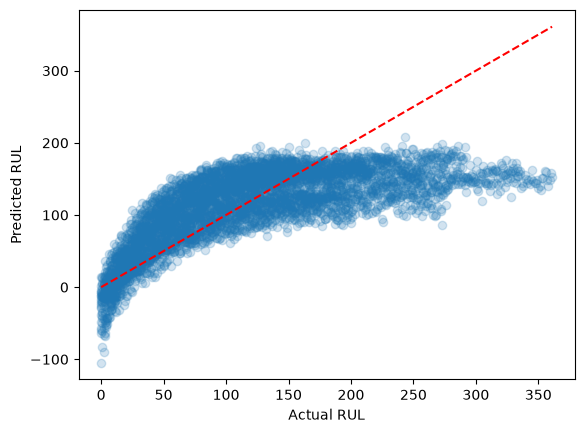

In [32]:
# Create scatter plot of performance
plt.scatter(validate_y, y_predict_val, alpha=0.2)
lim = max(validate_y.max(), y_predict_val.max())
plt.plot([0, lim], [0, lim], 'r--')
plt.xlabel("Actual RUL"); plt.ylabel("Predicted RUL")

## Linear Regression Analysis
The scatter plot shows non-linear data. The data flattens from 180 onward which means the signal is not useful after this. We need to cap at 150 cycles. 

In [33]:
train_set["RUL"] = train_set["RUL"].clip(upper=150)

In [34]:
# This function allows us to split data but maintain engine ID groups
# We will use a 80/20 split
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=27)

# Use next() to grap first fold slice
training_index, val_index = next(gss.split(train_set, groups=train_set["ID"]))

# create training set
train_fold = train_set.iloc[training_index]
# Create validation set
validate_fold = train_set.iloc[val_index]

# verify shape of new training df
display(train_fold.shape)

# verify shape of new validate df
display(validate_fold.shape)

(16198, 19)

(4433, 19)

In [35]:
# Remove columns that can leak data
# create a list of columns
drop = ['RUL', 'ID', 'Cycle']

# remove columns, create y set
train_x = train_fold.drop(columns=drop)
train_y = train_fold['RUL']

# remove columns, create y set
validate_x = validate_fold.drop(columns=drop)
validate_y = validate_fold['RUL']

# verify shape of new training df
display(train_x.shape)

# verify shape of new validate df
display(train_y.shape)

# verify shape of new training df
display(validate_x.shape)

# verify shape of new validate df
display(validate_y.shape)

(16198, 16)

(16198,)

(4433, 16)

(4433,)

In [36]:
# Create model object
lr = LinearRegression()

# Fit model to data
lr.fit(train_x, train_y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](16,)","[101.97,298.5 , -4.91,..., -1.62, 16.91, 27.66]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](16,)","['Op S1','Op S2','S2',...,'S17','S20','S21']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,7.11e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,16
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(16)


In [37]:
y_predict_train = lr.predict(train_x)
y_predict_val = lr.predict(validate_x)

In [38]:
# Create for loop to iterate through metric calculations
for name, y_true, y_pred in [("Training Score", train_y, y_predict_train), ("Validation score",   validate_y, y_predict_val),]:
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    # use f string create printout of results
    print(f"{name}: RMSE {rmse:.2f}  MAE {mae:.2f}  R^2 {r2:.3f}")

Training Score: RMSE 26.95  MAE 22.06  R^2 0.708
Validation score: RMSE 28.61  MAE 22.94  R^2 0.675


Text(0, 0.5, 'Predicted RUL')

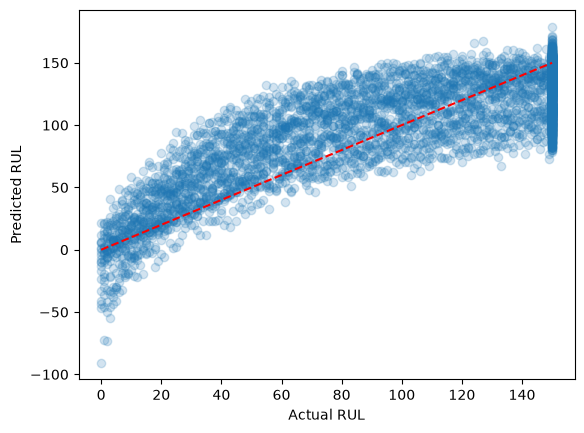

In [39]:
# Create scatter plot of performance
plt.scatter(validate_y, y_predict_val, alpha=0.2)
lim = max(validate_y.max(), y_predict_val.max())
plt.plot([0, 150], [0, 150], 'r--')
plt.xlabel("Actual RUL"); plt.ylabel("Predicted RUL")

## Linear Regression Summary
Capping the cycles allows the model to fit to the section of the data that is estimated to be the signal or contain the most signal. Observations between 250 and 350 RUL may not contribute to the signal. In addition, we have chosen not to attempt regularization because the data appears to be non-linear and it would better to move on to models that handle the data differently.

Validation **RMSE 28.61**  
Validation **R^2 0.675**

# Random Forest

In [40]:
# Create Random Forest model object
rf = RandomForestRegressor(n_estimators=100, max_depth=None, random_state=27, n_jobs=-1)
rf.fit(train_x, train_y)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",27
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [41]:
rf_pred_train = rf.predict(train_x)
rf_pred_val   = rf.predict(validate_x)

In [42]:
# Re-use code but change predict output vector names
# Display performance metrics for Random Forest
for name, y_true, y_pred in [("Training Score", train_y, rf_pred_train), ("Validation score",   validate_y, rf_pred_val),]:
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    # use f string create printout of results
    print(f"{name}: RMSE {rmse:.2f}  MAE {mae:.2f}  R^2 {r2:.3f}")

Training Score: RMSE 8.78  MAE 6.56  R^2 0.969
Validation score: RMSE 26.51  MAE 20.49  R^2 0.721


In [43]:
# Create panda series/ vector of importance using sklearn attribute
# we need to map feature importance to column names
feature_importance = pd.Series(rf.feature_importances_, index=train_x.columns)

# sort descending and take top 10
print(feature_importance.sort_values(ascending=False).head(10))

S11    0.529414
S9     0.139216
S4     0.081916
S12    0.045605
S14    0.026698
S7     0.026155
S15    0.023255
S21    0.019061
S2     0.017733
S3     0.017699
dtype: float64


### Feature Importance
Noteable features (top 3) are:  
**S11**: HPC outlet static pressure  
**S9**: Core speed  
**S4**: LPT outlet temperature

## Random Forest Hyperparameter Tuning
The default tree depth was "None" which causes overfitting. Next, we will sweep through some values of tree depth and compare the results

In [44]:
# Create an empty list to store results
rf_results = []

# For loop to iterate through tree depth
for depth in [3, 5, 8, 10, 15, 20, None]:
    # Use loop variable depth for depth argument
    m = RandomForestRegressor(n_estimators=100, max_depth=depth, random_state=27, n_jobs=-1)
    m.fit(train_x, train_y)
    tr = np.sqrt(mean_squared_error(train_y, m.predict(train_x)))
    va = np.sqrt(mean_squared_error(validate_y, m.predict(validate_x)))
    # With each loop add values to list
    rf_results.append({"max_depth": depth, "train_rmse": tr, "val_rmse": va})
    
    # Print result of each iteration as part of the loop
    print(f"depth={str(depth):>4}: training {tr:6.2f}  validation {va:6.2f}  train/validation gap {va-tr:6.2f}")

depth=   3: training  27.65  validation  29.53  train/validation gap   1.88
depth=   5: training  24.53  validation  27.52  train/validation gap   3.00
depth=   8: training  21.71  validation  26.56  train/validation gap   4.85
depth=  10: training  19.41  validation  26.39  train/validation gap   6.98
depth=  15: training  12.85  validation  26.40  train/validation gap  13.54
depth=  20: training   9.63  validation  26.47  train/validation gap  16.84
depth=None: training   8.78  validation  26.51  train/validation gap  17.73


## Random Forest Summary
After iterating through various tree depths, the winner a tree with depth of 10. This is according to a RMSE of 26.39, which is the lowest. Although the RMSE difference between the full depth and best depth is less significant what is significant is the difference in model complexity and resources needed.

# Gradient Boost

In [45]:
# Create model object
# Defaults: n_estimators=100, learning_rate=0.1, max_depth=3, random_state=None
gb = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=27)

# Train model on training data
# Same data as LR and RF
gb.fit(train_x, train_y)

# Evaluate model using both training and validation data
gb_pred_train = gb.predict(train_x)
gb_pred_val = gb.predict(validate_x)


In [46]:
# Display performance metrics for Gradient Boost
for name, y_true, y_pred in [("Training Score", train_y, gb_pred_train), ("Validation score",   validate_y, gb_pred_val),]:
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    # use f string and create a printout to compare results
    print(f"{name}: RMSE {rmse:.2f}  MAE {mae:.2f}  R^2 {r2:.3f}")

Training Score: RMSE 22.54  MAE 17.13  R^2 0.796
Validation score: RMSE 26.54  MAE 20.51  R^2 0.720


In [47]:
# Create an empty list to store results
gb_results = []

# For loop to iterate through n_estimators
for n_estimators in [50, 100, 200, 500, 1000]:
    # Use loop variable n_estimators for n_estimators argument
    m = GradientBoostingRegressor(n_estimators=n_estimators, learning_rate=0.1, max_depth=3, random_state=27)
    m.fit(train_x, train_y)
    tr = np.sqrt(mean_squared_error(train_y, m.predict(train_x)))
    va = np.sqrt(mean_squared_error(validate_y, m.predict(validate_x)))
    # With each loop add values to list
    gb_results.append({"n_estimators": n_estimators, "train_rmse": tr, "val_rmse": va})
    
    # Print result of each iteration as part of the loop
    print(f"n_estimators={str(n_estimators):>4}: training {tr:6.2f}  validation {va:6.2f}  train/validation gap {va-tr:6.2f}")

n_estimators=  50: training  22.96  validation  26.64  train/validation gap   3.67
n_estimators= 100: training  22.54  validation  26.54  train/validation gap   4.00
n_estimators= 200: training  22.02  validation  26.50  train/validation gap   4.48
n_estimators= 500: training  20.82  validation  26.58  train/validation gap   5.76
n_estimators=1000: training  19.19  validation  26.81  train/validation gap   7.63


## Non-linear Model Performance

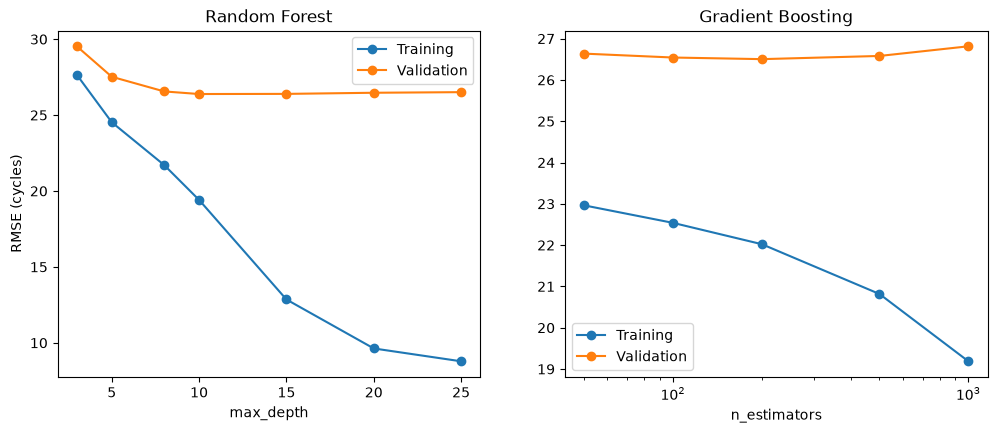

In [48]:
# Create two plots to compare non-linear models
# Plot need to be side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Settings for Random Forest
rf_df = pd.DataFrame(rf_results)
rf_df["depth_plot"] = [3, 5, 8, 10, 15, 20, 25]   # None plotted as 25
ax1.plot(rf_df.depth_plot, rf_df.train_rmse, "o-", label="Training")
ax1.plot(rf_df.depth_plot, rf_df.val_rmse, "o-", label="Validation")
ax1.set_xlabel("max_depth"); ax1.set_ylabel("RMSE (cycles)")
ax1.set_title("Random Forest"); ax1.legend()

# Settings for Gradient boost Plot
gb_df = pd.DataFrame(gb_results)
ax2.plot(gb_df.n_estimators, gb_df.train_rmse, "o-", label="Training")
ax2.plot(gb_df.n_estimators, gb_df.val_rmse, "o-", label="Validation")
ax2.set_xlabel("n_estimators"); ax2.set_xscale("log")
ax2.set_title("Gradient Boosting"); ax2.legend()

In [49]:
# Final Model Comparison

In [50]:
# Groups test_set by engine, then takes last value
# this represents failure cycle
test_last = test_set.groupby("ID").last().reset_index()

# Verify it shows last cycle
# mean should match NASA data
test_last["Cycle"].describe()

count    100.000000
mean     130.960000
std       53.593479
min       31.000000
25%       88.750000
50%      133.500000
75%      164.250000
max      303.000000
Name: Cycle, dtype: float64

In [51]:
# Drop Columns that can leak data
test_x = test_last.drop(columns=["ID", "Cycle"])

In [52]:
# This is test true labels but capped from our LR evaluation results
test_y = true_value["RUL"].clip(upper=150)

In [53]:
# Create a FOR loop to compare our three models
for name, model in [("Linear Regression", lr), ("Random Forest", rf), ("Gradient Boosting", gb)]:
    # use same test set- not validation
    pred = model.predict(test_x)

    # Compare based on the three metrics already used
    rmse = np.sqrt(mean_squared_error(test_y, pred))
    mae = mean_absolute_error(test_y, pred)
    r2 = r2_score(test_y, pred)

    # Stay within the loop print each iteration
    print(f"{name:18}: RMSE {rmse:6.2f}  MAE {mae:6.2f}  R^2 {r2:.3f}")

Linear Regression : RMSE  23.91  MAE  19.18  R^2 0.669
Random Forest     : RMSE  21.60  MAE  15.77  R^2 0.730
Gradient Boosting : RMSE  21.83  MAE  15.64  R^2 0.724


## Model Comparison based on Test Evaluation
The RMSE performance of the test set is better than the evaluation because the test is a snapshot while the validation tests on every cycle. 

# Summary
Based on the final test evaluation, the models can be ranked as follows: Random Forest, Gradient Boosting, and Linear Regression. Both tree models are essentially tied for first place and both beat linear regression. 


Initially the linear regression model appeared to overfit with in-sample RMSE 41.00 and an out-of-sample RMSE of 56.26. However, by introducing capping at 150 cycles, the train/validate gap reduced from in-sample RMSE 26.95 and an out-of-sample RMSE of 28.61. Capping removed the lack of a signal and revealed the real issue was not overfitting but the bias. 

For this reason, non-linear ensamble models Random Forest and Gradient Boost were introduced. Trees are not based on the shape of the data. Yet, both these models build trees differently. With Random Forest, bagging produces stability. With Gradient Boost, each tree is built sequentially. They deal with non-linear data differently but produce similar accuracy and beat the baseline of Linear Regression.

# References

**Dataset**:   
Saxena, A., & Goebel, K. (2008). Turbofan Engine Degradation Simulation Data Set. NASA Prognostics Data Repository, NASA Ames Research Center, Moffett Field, CA. https://data.nasa.gov/dataset/simulating-degradation-data-for-prognostic-algorithm-development

**Research paper**:   
Saxena, A., Goebel, K., Simon, D., & Eklund, N. (2008). Damage Propagation Modeling for Aircraft Engine Run-to-Failure Simulation. Proceedings of the 1st International Conference on Prognostics and Health Management (PHM08), Denver, CO, 1–9.

**Dataset links**:   
https://www.kaggle.com/datasets/behrad3d/nasa-cmaps

https://data.nasa.gov/dataset/simulating-degradation-data-for-prognostic-algorithm-development

**Sensor descriptions link**:   
https://www.google.com/url?sa=i&source=web&rct=j&url=https://junhyundata.tistory.com/102&opi=89978449&psig=AOvVaw3I55vTlK_LN70Op6uwsp_i&ust=1791649233033000

**Text book**:   
An Introduction to Statistical Learning with Applications in Python, 1st edition, by G. James, D. Witten, T. Hastie, R. Tibshirani & J. Taylor; free pdf download: https://www.statlearning.com/Links to an external site.

**Machine learning models**:   
https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.LinearRegression.html

### AI Notice
AI was used for spelling and grammar check in many cells. The content of the cells is original work.
AI was used to troubleshoot syntax errors and to troubleshoot notebook settings.